In [124]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.special import gammaln  # for log(y!) = gammaln(y+1)
from scipy.optimize import minimize
from patsy import dmatrix, build_design_matrices
from itertools import product
from scipy.stats import poisson

np.random.seed(2)

TIME_COL = "in Lund C"
BIN_MINUTES = 5
MORNING_START = "05:00:00"
MORNING_END = "11:00:00"

#helper function
def minutes_to_time(minutes):
    hours = minutes // 60
    mins = minutes % 60
    return f"{hours:02d}:{mins:02d}:00"

## Loading the commuter data

Import the CSV file and inspect its rows, columns and commute directions. Shuffling the rows changes their order only it does not make simulated data more realistic or change the underlying counts. The later steps use the in Lund C time and commute_type to build separate arrival and departure series.

In [125]:
csv_path = Path("data/Lund_C_20261020_all_commuters.csv")

df = pd.read_csv(csv_path)
df = df.sample(frac=1, random_state=42).reset_index(drop=True) # Dataframe looks too simulated. Shuffling might help

print(f"Rows: {len(df):,}")
print("\nColumns:")
print(df.columns.tolist())
print()
print(df["commute_type"].value_counts())

df.head()

Rows: 66,728

Columns:
['worker_id', 'sex', 'residential_municipality', 'workplace_municipality', 'origin_station', 'destination_station', 'desired_arrival', 'commute_type', 'train_to_take', 'waiting_time', 'in Lund C']

commute_type
arrive    39940
leave     26788
Name: count, dtype: int64


,worker_id,sex,residential_municipality,workplace_municipality,origin_station,destination_station,desired_arrival,commute_type,train_to_take,waiting_time,in Lund C
0,38517,kvinnor,Staffanstorp,Malmö,Lund C,Malmö C,08:32:00,leave,08:08:00,00:10:00,07:58:00
1,16618,män,Malmö,Lund,Malmö C,Lund C,08:45:00,arrive,08:41:00,00:00:00,08:41:00
2,48007,kvinnor,Malmö,Staffanstorp,Malmö C,Lund C,08:41:00,arrive,08:39:00,00:00:00,08:39:00
3,60462,kvinnor,Lund,Malmö,Lund C,Malmö C,08:31:00,leave,08:08:00,00:06:00,08:02:00
4,14816,män,Malmö,Lund,Malmö C,Lund C,08:31:00,arrive,08:26:00,00:00:00,08:26:00


## Defining the morning observation window

Convert each HH:MM:SS value into minutes after midnight, which makes time arithmetic straightforward. Keep observations from 05:00 inclusive to 11:00 exclusive so every record belongs to the same six-hour morning period. 

In [126]:
# Convert HH:MM:SS to minutes after midnight
time_parsed = pd.to_datetime(df[TIME_COL], format="%H:%M:%S", errors="coerce")
df = df.loc[time_parsed.notna()].copy()
time_parsed = time_parsed.loc[df.index]

df["minutes_after_midnight"] = (
    time_parsed.dt.hour * 60 + time_parsed.dt.minute + time_parsed.dt.second / 60
)

start_min = 5 * 60
end_min = 11 * 60
morning = df[df["minutes_after_midnight"].between(start_min, end_min, inclusive="left")].copy()

morning["minutes_after_midnight"]

0        478.0
1        521.0
2        519.0
3        482.0
4        506.0
         ...  
66723    496.0
66724    482.0
66725    496.0
66726    492.0
66727    506.0
Name: minutes_after_midnight, Length: 66728, dtype: float64

## Aggregating records into five-minute counts

Floor each event time to the start of its five-minute bin, then count records separately for arrivals and departures. The complete grid adds bins with zero commuters, so the model sees a continuous time series rather than silently dropping empty intervals. Each row in counts is one direction–time-bin combination.

In [127]:
# Floor each event to its five-minute interval.
morning["bin_minute"] = (
    np.floor(morning["minutes_after_midnight"] / BIN_MINUTES) * BIN_MINUTES
).astype(int)

# Include empty intervals so the time series is continuous.
all_bins = np.arange(start_min, end_min, BIN_MINUTES)
directions = ["arrive", "leave"]
counts = (
    morning.groupby(["commute_type", "bin_minute"])
    .size()
    .rename("count")
    .reset_index()
)

grid = pd.MultiIndex.from_product(
    [directions, all_bins], names=["commute_type", "bin_minute"]
).to_frame(index=False)
counts = grid.merge(counts, on=["commute_type", "bin_minute"], how="left")
counts["count"] = counts["count"].fillna(0).astype(int)
counts["time"] = counts["bin_minute"].map(
    lambda m: f"{int(m // 60):02d}:{int(m % 60):02d}"
)

print(f"Commuters in morning window: {len(morning):,}")
print(counts.groupby("commute_type")["count"].sum())
counts

Commuters in morning window: 66,728
commute_type
arrive    39940
leave     26788
Name: count, dtype: int64


,commute_type,bin_minute,count,time
0,arrive,300,0,05:00
1,arrive,305,0,05:05
2,arrive,310,0,05:10
3,arrive,315,0,05:15
4,arrive,320,0,05:20
...,...,...,...,...
139,leave,635,0,10:35
140,leave,640,0,10:40
141,leave,645,0,10:45
142,leave,650,0,10:50


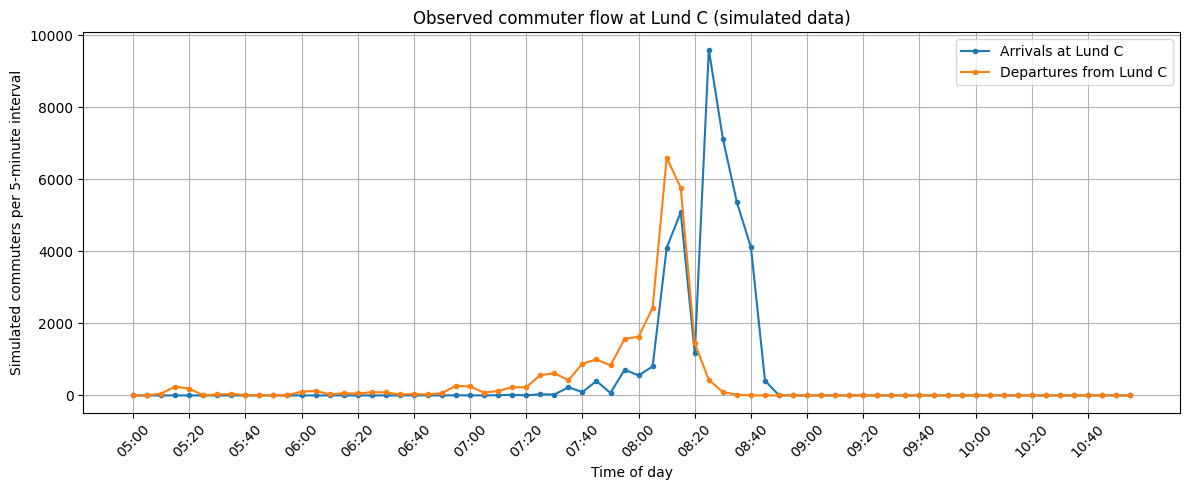

In [128]:
fig, ax = plt.subplots(figsize=(12, 5))

for direction, label in [("arrive", "Arrivals at Lund C"), ("leave", "Departures from Lund C")]:
    subset = counts[counts["commute_type"] == direction]
    ax.plot(subset["bin_minute"], subset["count"], marker=".", linewidth=1.5, label=label)

ticks = np.arange(min(subset["bin_minute"]), max(subset["bin_minute"]) + 1, 20)
ax.set_xticks(ticks, [minutes_to_time(int(x))[:5] for x in ticks])
ax.tick_params(axis="x", labelrotation=45)
ax.set_xlabel("Time of day")
ax.set_ylabel("Simulated commuters per 5-minute interval")
ax.set_title("Observed commuter flow at Lund C (simulated data)")
ax.grid()
ax.legend()
plt.tight_layout()
plt.show()

## Modeling the count pattern with Poisson regression and splines

Each response is the number of commuters in a five-minute interval, so a Poisson model is a natural starting point for non-negative count data. It models the expected count as $\lambda(t)=\exp(\eta(t))$, where $(\eta(t))$ is a linear combination of spline basis functions of time. The exponential link keeps predictions positive. Splines allow the curve to bend and capture morning peaks rather than imposing a straight-line trend. The functions below define the Poisson objective, fit coefficients, generate predictions, and evaluate candidate models with K-fold cross-validation.  

The negative log-likelihood is minimized to estimate the spline coefficients. For a Poisson response, the log-likelihood (apart from the constant $\log(y!)$) is $\sum_i[y_i\eta_i-\exp(\eta_i)]$. The build_model and predict functions construct the spline design matrix and return fitted means. kfold_validate splits observations into folds, fits on the training portion, and scores predictions on the held-out portion using mean squared error (MSE). Lower MSE indicates better average prediction accuracy under this metric.

In [129]:
def log_likelihood_poisson_glm(params, X, y):
    eta = X @ params
    lam = np.exp(eta)

    log_lik = np.sum(y * eta - lam)
    return -log_lik

def grad_poisson_glm(params, X, y):
    eta = X @ params
    lam = np.exp(eta)

    return -(X.T @ (y - lam)) 

def build_model(X, y, df, degree):
    # Create the spline design matrix
    strinp = f"bs(hour, df={str(df)}, degree={str(degree)}, include_intercept=True)- 1"
    modifiedX = np.asarray(dmatrix(strinp, data=X))

    # Initial parameter values
    #initial_beta = np.zeros(modifiedX.shape[1])
    initial_beta = np.full(modifiedX.shape[1], np.log(np.mean(y) + 1e-5))

    # Fit the Poisson regression
    result = minimize( log_likelihood_poisson_glm, initial_beta, args=(modifiedX, y), jac=grad_poisson_glm, method="BFGS" )
    beta_hat = result.x

    return beta_hat

def predict(beta_hat, X, df, degree):
    strinp = f"bs(hour, df={str(df)}, degree={str(degree)}, include_intercept=True)- 1"
    modifiedX = np.asarray(dmatrix(strinp, data=X))
    eta_hat = modifiedX @ beta_hat
    pred_mean = np.exp(eta_hat)
    return pred_mean

def kfold_validate(x, y, K, df, degree, random_seed= None, plot=False):
    "Divides the data into k folds"
    rng = np.random.default_rng(random_seed)
    idx = rng.permutation(len(y))

    x_randomized = x.iloc[idx].reset_index(drop=True)
    y_randomized = y.iloc[idx].reset_index(drop=True)

    assert len(x) % K == 0, "K must divide the number of observations equally."
    assert len(x) == len(y), "x and y must have the same number of observations."
    
    cutoff = len(x)//K
    
    idx  = list(range(len(x)))
    kMSEs = np.zeros((K),dtype=float)
    betas = []
    
    for k in range(K):
        val_idx   = idx[k*cutoff:(k+1)*cutoff]
        train_idx = idx[:k*cutoff] + idx[(k+1)*cutoff:]
        
        xval = x_randomized.iloc[val_idx]
        xtrain = x_randomized.iloc[train_idx]
        
        yval = y_randomized.iloc[val_idx]
        ytrain = y_randomized.iloc[train_idx]

        beta_hat = build_model(xtrain, ytrain, df, degree)
        y_pred = predict(beta_hat, xval, df, degree)
        kMSEs[k]= np.mean( ((yval - y_pred)**2) )
        betas.append(beta_hat)

    MSE = np.mean(kMSEs)
    return MSE, betas[np.argmin(kMSEs)]

## Comparing spline complexity with cross-validation

The number of spline degrees of freedom (df) controls how flexible the curve can be, while degree sets the polynomial degree of each spline piece. This cell evaluates the allowed combinations separately for arrivals and departures. Three-fold cross-validation rotates which third of the observations is held out, the mean squared error across folds estimates how well each setting predicts unseen bins. The best setting is selected independently for each direction.

In [130]:
counts["hour"] = counts["bin_minute"] / 60

#Experiment with both df and degrees
DEGREE = 3
dofs = np.arange(DEGREE + 2, 30 + 1)

combinations = [(n_df, DEGREE) for n_df in dofs]

degMSEs = [[],[]] #arrive, leave
betas   = [[],[]] 

Xarrival = counts[counts["commute_type"] == "arrive"].copy()
yarrival = Xarrival["count"]

Xdeparture = counts[counts["commute_type"] == "leave"].copy()
ydeparture = Xdeparture["count"]

for df, degree in combinations:
    
    arr_mse, arr_betas = kfold_validate(Xarrival, yarrival, 3, df, degree)
    dep_mse, dep_betas = kfold_validate(Xdeparture, ydeparture, 3, df, degree)

    print(f"Validating (df,degree): ({df:2} , {degree:2})  arrive model MSE = {arr_mse:.5f},  departure model MSE = {dep_mse:.5f}", end="\r", flush = True)
    
    degMSEs[0].append(arr_mse)
    degMSEs[1].append(dep_mse)

    betas[0].append(arr_betas)
    betas[1].append(dep_betas)

/tmp/ipykernel_2458/3556906558.py:3: RuntimeWarning: overflow encountered in exp
  lam = np.exp(eta)
/tmp/ipykernel_2458/3556906558.py:10: RuntimeWarning: overflow encountered in exp
  lam = np.exp(eta)
/tmp/ipykernel_2458/3556906558.py:3: RuntimeWarning: overflow encountered in exp
  lam = np.exp(eta)


/tmp/ipykernel_2458/3556906558.py:3: RuntimeWarning: overflow encountered in exp
  lam = np.exp(eta)
/tmp/ipykernel_2458/3556906558.py:10: RuntimeWarning: overflow encountered in exp
  lam = np.exp(eta)


/tmp/ipykernel_2458/3556906558.py:33: RuntimeWarning: overflow encountered in exp
  pred_mean = np.exp(eta_hat)
/tmp/ipykernel_2458/3556906558.py:3: RuntimeWarning: overflow encountered in exp
  lam = np.exp(eta)
/tmp/ipykernel_2458/3556906558.py:10: RuntimeWarning: overflow encountered in exp
  lam = np.exp(eta)
/tmp/ipykernel_2458/3556906558.py:3: RuntimeWarning: overflow encountered in exp
  lam = np.exp(eta)
/tmp/ipykernel_2458/3556906558.py:10: RuntimeWarning: overflow encountered in exp
  lam = np.exp(eta)
/tmp/ipykernel_2458/3556906558.py:3: RuntimeWarning: overflow encountered in exp
  lam = np.exp(eta)
/tmp/ipykernel_2458/3556906558.py:10: RuntimeWarning: overflow encountered in exp
  lam = np.exp(eta)
/tmp/ipykernel_2458/3556906558.py:3: RuntimeWarning: overflow encountered in exp
  lam = np.exp(eta)
/tmp/ipykernel_2458/3556906558.py:10: RuntimeWarning: overflow encountered in exp
  lam = np.exp(eta)


/tmp/ipykernel_2458/3556906558.py:3: RuntimeWarning: overflow encountered in exp
  lam = np.exp(eta)
/tmp/ipykernel_2458/3556906558.py:10: RuntimeWarning: overflow encountered in exp
  lam = np.exp(eta)


/tmp/ipykernel_2458/3556906558.py:33: RuntimeWarning: overflow encountered in exp
  pred_mean = np.exp(eta_hat)


...

/tmp/ipykernel_2458/3556906558.py:33: RuntimeWarning: overflow encountered in exp
  pred_mean = np.exp(eta_hat)
/tmp/ipykernel_2458/3556906558.py:33: RuntimeWarning: overflow encountered in exp
  pred_mean = np.exp(eta_hat)


/tmp/ipykernel_2458/3556906558.py:33: RuntimeWarning: overflow encountered in exp
  pred_mean = np.exp(eta_hat)
/tmp/ipykernel_2458/3556906558.py:3: RuntimeWarning: overflow encountered in exp
  lam = np.exp(eta)
/tmp/ipykernel_2458/3556906558.py:10: RuntimeWarning: overflow encountered in exp
  lam = np.exp(eta)
/tmp/ipykernel_2458/3556906558.py:3: RuntimeWarning: overflow encountered in exp
  lam = np.exp(eta)
/tmp/ipykernel_2458/3556906558.py:10: RuntimeWarning: overflow encountered in exp
  lam = np.exp(eta)
/tmp/ipykernel_2458/3556906558.py:3: RuntimeWarning: overflow encountered in exp
  lam = np.exp(eta)
/tmp/ipykernel_2458/3556906558.py:10: RuntimeWarning: overflow encountered in exp
  lam = np.exp(eta)
/tmp/ipykernel_2458/3556906558.py:3: RuntimeWarning: overflow encountered in exp
  lam = np.exp(eta)
/tmp/ipykernel_2458/3556906558.py:33: RuntimeWarning: overflow encountered in exp
  pred_mean = np.exp(eta_hat)
/tmp/ipykernel_2458/3556906558.py:33: RuntimeWarning: overflow enc

/tmp/ipykernel_2458/3556906558.py:3: RuntimeWarning: overflow encountered in exp
  lam = np.exp(eta)
/tmp/ipykernel_2458/3556906558.py:10: RuntimeWarning: overflow encountered in exp
  lam = np.exp(eta)
/tmp/ipykernel_2458/3556906558.py:3: RuntimeWarning: overflow encountered in exp
  lam = np.exp(eta)
/tmp/ipykernel_2458/3556906558.py:33: RuntimeWarning: overflow encountered in exp
  pred_mean = np.exp(eta_hat)


/tmp/ipykernel_2458/3556906558.py:3: RuntimeWarning: overflow encountered in exp
  lam = np.exp(eta)
/tmp/ipykernel_2458/3556906558.py:10: RuntimeWarning: overflow encountered in exp
  lam = np.exp(eta)
/tmp/ipykernel_2458/3556906558.py:3: RuntimeWarning: overflow encountered in exp
  lam = np.exp(eta)


/tmp/ipykernel_2458/3556906558.py:33: RuntimeWarning: overflow encountered in exp
  pred_mean = np.exp(eta_hat)


In [131]:
arr_idx, dep_idx = np.argmin(degMSEs[0]), np.argmin(degMSEs[1])
opt_df_arive , opt_degree_arive = combinations[arr_idx]
opt_df_leave , opt_degree_leave = combinations[dep_idx]
opt_arr_betas, opt_dep_betas = betas[0][arr_idx], betas[1][dep_idx]

print("Cross Validation Error")
print("Arrive Model: ", degMSEs[0][arr_idx])
print("Leave Model: ", degMSEs[1][dep_idx])
print()
print("Optimal hyperparameters:" )
print("df arrive model ",opt_df_arive)
print("degree arrive model ",opt_degree_arive)
print("df leave model ",opt_df_leave)
print("degree leave model ",opt_degree_leave)

Cross Validation Error
Arrive Model:  1799377.4431317335
Leave Model:  507793.5178386815

Optimal hyperparameters:
df arrive model  10
degree arrive model  3
df leave model  21
degree leave model  3


## Fitting the selected models and calculate predictions

Using the selected spline settings, construct the design matrix for each direction and calculate $\hat\lambda_i=\exp(X_i\hat\eta)$, the model's expected number of commuters in each five-minute bin. The cell also calculates the 95% central interval of a Poisson count distribution with mean $\hat\lambda_i$. These bounds describe plausible counts under the fitted Poisson assumption, they are not confidence intervals for uncertainty in the estimated mean. The resulting table keeps observed counts, fitted means, time labels, and interval bounds together for plotting and peak detection.

In [132]:
models_custom = {}
predictions_custom = []

for direction in ["arrive", "leave"]:

    d = counts[counts["commute_type"] == direction].copy()
    y = d["count"].to_numpy()

    # Keep the optimal hyperparameters selected by cross-validation
    if direction == "arrive":
        df, degree = opt_df_arive, opt_degree_arive
    else:
        df, degree = opt_df_leave, opt_degree_leave

    # Refit the model using ALL observations
    beta_hat = build_model(d, y, df, degree)

    # Construct the spline design matrix on the full dataset
    spline_formula = f"bs(hour, df={str(df)}, degree={str(degree)}, include_intercept=True)- 1"
    X = np.asarray(dmatrix(spline_formula, data=d))

    # Predicted expected counts per 5-minute interval
    eta_hat = X @ beta_hat
    pred_mean = np.exp(eta_hat)

    # 95% Poisson prediction intervals for counts
    lower, upper = poisson.interval(0.95, mu=pred_mean)

    models_custom[direction] = {
        "beta": beta_hat,
        "df": df,
        "degree": degree,
    }

    pred = d[["bin_minute", "time", "hour"]].copy()
    pred["observed"] = y
    pred["predicted"] = pred_mean
    pred["lower_95"] = lower
    pred["upper_95"] = upper
    pred["commute_type"] = direction

    predictions_custom.append(pred)

predictions_custom = pd.concat(
    predictions_custom, ignore_index=True
)

display(predictions_custom.head())


,bin_minute,time,hour,observed,predicted,lower_95,upper_95,commute_type
0,300,05:00,5.000000,0,8.246198e-102,0.0,0.0,arrive
1,305,05:05,5.083333,0,0.000000e+00,0.0,0.0,arrive
2,310,05:10,5.166667,0,0.000000e+00,0.0,0.0,arrive
3,315,05:15,5.250000,0,0.000000e+00,0.0,0.0,arrive
4,320,05:20,5.333333,0,0.000000e+00,0.0,0.0,arrive


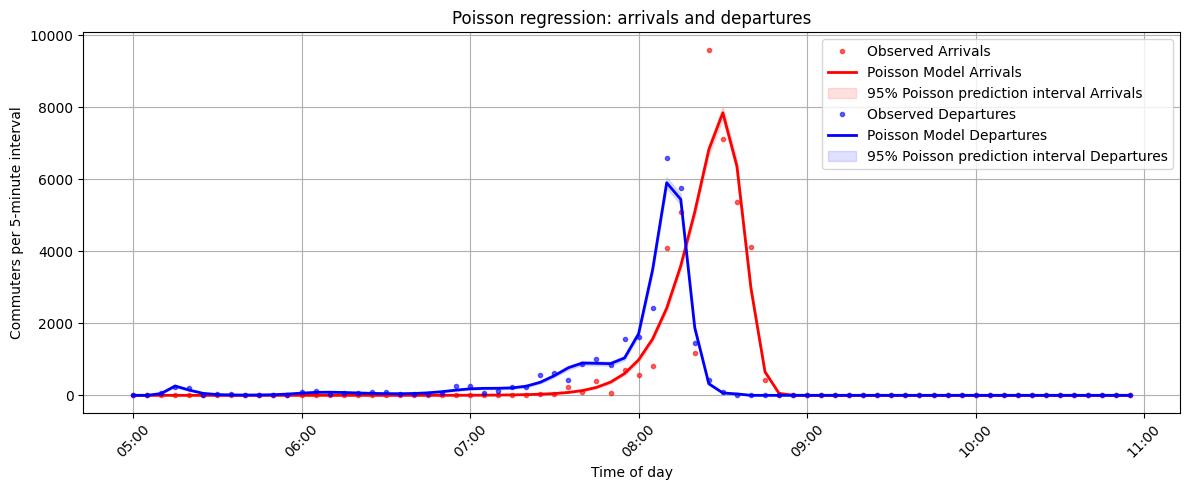

In [133]:
fig, ax = plt.subplots(figsize=(12, 5))

for direction, label, color in [("arrive", "Arrivals", 'red'), ("leave", "Departures", 'blue')]:
    pred = predictions_custom[predictions_custom["commute_type"] == direction]

    ax.plot(pred["hour"], pred["observed"], ".", alpha=0.6, label=f"Observed {label}", color=color)
    ax.plot(pred["hour"], pred["predicted"], linewidth=2, label=f"Poisson Model {label}", color=color)
    #ax.fill_between(pred["hour"], pred["predicted"] - pred["lower_95"], pred["predicted"] + pred["upper_95"], alpha=0.12, label=f"95% CI {label}", color=color)
    ax.fill_between(pred["hour"], pred["lower_95"], pred["upper_95"], alpha=0.12, label=f"95% Poisson prediction interval {label}", color=color)

    ticks = np.arange(min(pred["hour"]), max(pred["hour"]) + 1, 1)
    ax.set_xticks(ticks, [minutes_to_time(int(x*60))[:5] for x in ticks])
    ax.tick_params(axis="x", labelrotation=45)

ax.set_xlabel("Time of day")
ax.set_ylabel("Commuters per 5-minute interval")
ax.set_title("Poisson regression: arrivals and departures")
ax.grid()
ax.legend()
plt.tight_layout()
plt.show()

## Identifying rush-hour peaks

For each direction, compare two different quantities, the observed peak is the five-minute bin with the largest recorded count, while the fitted peak is the bin with the largest model-estimated mean. They need not be identical because the spline smooths short-lived fluctuations. The interval bounds shown here come from a Poisson distribution with the fitted mean. Strictly speaking, these are prediction intervals for a count, not confidence intervals for the underlying mean.

In [134]:

def peak_summary(frame, value_col):
    """Return the peak count and its exact 5-minute time interval."""
    idx = frame[value_col].idxmax()
    row = frame.loc[idx]

    start_minute = int(row["bin_minute"])
    end_minute = start_minute + BIN_MINUTES

    return {
        "interval": (
            f"{minutes_to_time(start_minute)[:5]}–"
            f"{minutes_to_time(end_minute)[:5]}"
        ),
        "count": float(row[value_col]),
    }


rows = []

for direction in ["arrive", "leave"]:
    p = predictions_custom[
        predictions_custom["commute_type"] == direction
    ].copy()

    # Peak in the observed data
    observed_peak = peak_summary(p, "observed")

    # Peak in the fitted Poisson model
    fitted_peak = peak_summary(p, "predicted")

    # Retrieve the model's existing 95% Poisson interval
    fitted_idx = p["predicted"].idxmax()
    fitted_row = p.loc[fitted_idx]

    rows.append({
        "Direction": (
            "Arrivals at Lund C"
            if direction == "arrive"
            else "Departures from Lund C"
        ),
        "Busiest observed interval": observed_peak["interval"],
        "Observed commuters": int(observed_peak["count"]),
        "Highest fitted interval": fitted_peak["interval"],
        "Fitted mean commuters": round(fitted_peak["count"], 2),
        "95% interval lower bound": int(fitted_row["lower_95"]),
        "95% interval upper bound": int(fitted_row["upper_95"]),
    })


print("Rush-hour peak analysis - Lund C")
print("Each interval represents a 5-minute period.\n")

for row in rows:
    print(f"{row['Direction']}")
    print(
        f"  Busiest observed interval: "
        f"{row['Busiest observed interval']} "
        f"({row['Observed commuters']} commuters)"
    )
    print(
        f"  Highest fitted interval: "
        f"{row['Highest fitted interval']} "
        f"(mean = {row['Fitted mean commuters']:.2f} commuters)"
    )
    print(
        f"  95% Poisson prediction interval at fitted peak: "
        f"{row['95% interval lower bound']}–"
        f"{row['95% interval upper bound']} commuters"
    )
    print()

Rush-hour peak analysis - Lund C
Each interval represents a 5-minute period.

Arrivals at Lund C
  Busiest observed interval: 08:25–08:30 (9607 commuters)
  Highest fitted interval: 08:30–08:35 (mean = 7851.30 commuters)
  95% Poisson prediction interval at fitted peak: 7678–8025 commuters

Departures from Lund C
  Busiest observed interval: 08:10–08:15 (6607 commuters)
  Highest fitted interval: 08:10–08:15 (mean = 5907.59 commuters)
  95% Poisson prediction interval at fitted peak: 5757–6059 commuters

